# Methane author-matched run: Stage 2, 200,000 epochs (evaluated: best snapshot, epoch 180,000)

- **Data:** `chemkan/data/generated/methane.npz` (GRI-Mech 3.0 in Cantera, 52 species + T): 36
  constant-pressure conditions, T0 = 1400-1650 K in 50 K steps x phi = 0.5-1.5 in 0.2 steps;
  35 for training and the held-out condition T0 1550 K, phi 1.3; 100 observation times over
  5 ms. Stage 1 takes the observed temperature from `methane_temperature_20000.npz`.
  Methane is the project proposal's extension; the paper has no methane results.
- **Trainer:** `chemkan/scripts/author_repo_match/train_author_matched_hydrogen.py --system methane`,
  seed 0: the hydrogen author-matched settings (Adam lr 2e-3, Tsit5 rtol 1e-6 / atol 1e-8,
  batched float32, direct autograd, no warm-up, PINN alpha 1e-4), t_ref = 5 ms.
- **History of the run:** Stage 1 on the JupyterHub to 28,000 epochs, continued on the Mac and
  stopped at ~54,800; Stage 2 starts from the **epoch-50,000 Stage-1 archive** and was
  extended in place (`S2_seed0`, `--resume --epochs`) to 100k, 150k and 200,000 epochs.
  The final epoch-200,000 model (`stage2_final.pt` = `archive/stage2_S2_seed0_epoch200000.pt`)
  sits on a training-loss spike; this notebook evaluates the **best 5,000-epoch snapshot by
  training-condition full-trajectory MSE, epoch 180,000** (selection below; the held-out
  condition is not used for it). The loss was still decreasing at 200k: not converged.
- **Loss convention:** time-averaged MSE in normalized coordinates (Eq. 18 / 100 time points).
  Training losses: last epoch and the median of the previous 200 epochs.
- **One seed;** read differences between conditions as single-run values.

In [1]:
%matplotlib inline
import csv
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "chemkan/scripts/author_repo_match"))
import plot_trajectory as pt  # noqa: E402  (load_model / load_reference / predict)

torch.set_num_threads(2)                       # leave the CPU to the running training
RUN = ROOT / "results/experiments/methane/author_matched/main"
CKPT = RUN / "S2_seed0/archive/stage2_S2_seed0_epoch180000.pt"
ckpt = torch.load(CKPT, map_location="cpu", weights_only=False)
model = pt.load_model(ckpt)
ref = pt.load_reference(model["data"])
cfg = ckpt["config"]
print("checkpoint:", CKPT.relative_to(ROOT), "| stage", ckpt["stage"], "| epochs", model["epochs"])
print("parameters:", cfg["architecture"]["parameter_count"], "| states:", len(ref["names"]),
      "| conditions:", len(ref["ics"]), f"({int(ref['is_test'].sum())} held out)")
print("Stage-1 source:", cfg["stage1_archive"]["path"].split("/")[-1],
      "| epochs", cfg["stage1_archive"]["epochs_completed"])

checkpoint: results/experiments/methane/author_matched/main/S2_seed0/archive/stage2_S2_seed0_epoch180000.pt | stage 2 | epochs 180000
parameters: 1892 | states: 53 | conditions: 36 (1 held out)
Stage-1 source: stage1_S1_seed0_epoch50000.pt | epochs 50000


## Training history

Time-averaged MSE per epoch (grey) and the median over the previous 1,000 epochs (blue).
Stage 1 fits the 52 species with the observed temperature as input; Stage 2 also predicts the
temperature, so the two stages' values are not directly comparable.

Stage 1: epochs logged 54,790; best single epoch 9.161e-04 at 24,695; at epoch 50,000: 2.214e-03 / median of previous 200 2.227e-03


Stage 2: epochs logged 200,000; best single epoch 1.170e-03 at 199,652; at epoch 180,000: 1.223e-03 / median of previous 200 1.741e-03


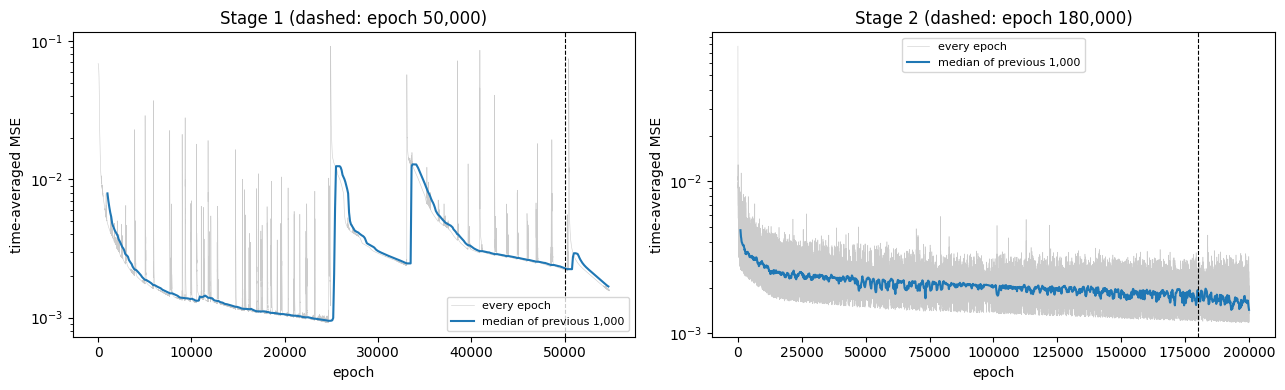

In [2]:
def history(path):
    with open(path) as f:
        rows = list(csv.DictReader(f))
    return (np.array([int(r["epoch"]) for r in rows]),
            np.array([float(r["mse_time_avg"]) for r in rows]))

def window_median(v, w=1000, step=100):
    idx = np.arange(w, len(v) + 1, step)
    return idx, np.array([np.median(v[i - w:i]) for i in idx])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, path, stop) in zip(axes, [
        ("Stage 1", RUN / "S1_seed0/stage1_history.csv", 50000),
        ("Stage 2", RUN / "S2_seed0/stage2_history.csv", 180000)]):
    ep, v = history(path)
    ax.semilogy(ep, v, color="0.8", lw=0.4, label="every epoch")
    i, m = window_median(v)
    ax.semilogy(ep[i - 1], m, color="tab:blue", lw=1.5, label="median of previous 1,000")
    ax.axvline(stop, color="k", ls="--", lw=0.8)
    ax.set_title(f"{name} (dashed: epoch {stop:,})")
    ax.set_xlabel("epoch"); ax.set_ylabel("time-averaged MSE"); ax.legend(fontsize=8)
    best = int(np.argmin(v))
    upto = v[:stop]
    print(f"{name}: epochs logged {ep[-1]:,}; best single epoch {v[best]:.3e} at {ep[best]:,}; "
          f"at epoch {stop:,}: {upto[-1]:.3e} / median of previous 200 {np.median(upto[-200:]):.3e}")
fig.tight_layout()

## Snapshot selection

The last Stage-2 epochs are spiky, and the final model (epoch 200,000) landed on a spike. Every
5,000-epoch snapshot from 175k is integrated over the 36 conditions (full trajectory, training
solver); the model is chosen by the **mean over the 35 training conditions** only. The
held-out column is shown for information and plays no part in the choice.


In [3]:
rows = []
for e in range(175000, 200001, 5000):
    m = pt.load_model(torch.load(RUN / f"S2_seed0/archive/stage2_S2_seed0_epoch{e}.pt",
                                 map_location="cpu", weights_only=False))
    sp = m["u_max"] - m["u_min"]
    mse = np.array([((pt.predict(m, ref, i, ref["t"])
                      - (np.concatenate([ref["states"][i][:, :len(ref["species"])],
                                         ref["temperature"][:, i:i + 1]], axis=1) - m["u_min"]) / sp) ** 2).mean()
                    for i in range(len(ref["ics"]))])
    tr = mse[~ref["is_test"]]
    rows.append({"epoch": e, "train mean": tr.mean(), "train median": np.median(tr),
                 "train max": tr.max(), "held-out": mse[ref["is_test"]][0]})
snap = pd.DataFrame(rows).set_index("epoch")
print("selected (lowest training mean):", int(snap["train mean"].idxmin()))
snap.style.format("{:.3e}")


selected (lowest training mean): 180000


,train mean,train median,train max,held-out
epoch,,,,
175000,1.636e-03,1.265e-03,5.957e-03,1.287e-03
180000,1.220e-03,9.724e-04,3.187e-03,1.163e-03
185000,1.224e-03,9.873e-04,3.194e-03,1.083e-03
190000,1.227e-03,1.005e-03,3.259e-03,1.280e-03
195000,1.759e-03,1.093e-03,7.539e-03,1.142e-03
200000,2.885e-03,1.516e-03,1.181e-02,1.274e-03


## Error per condition

Every condition integrated from its initial state alone (full trajectory), on the 100
observation times, with the training solver. Time-averaged MSE over all 53 states in the
training normalization.

train (35): median 9.724e-04, min 4.497e-04, max 3.187e-03
held-out 1550 K / phi 1.3: 1.163e-03


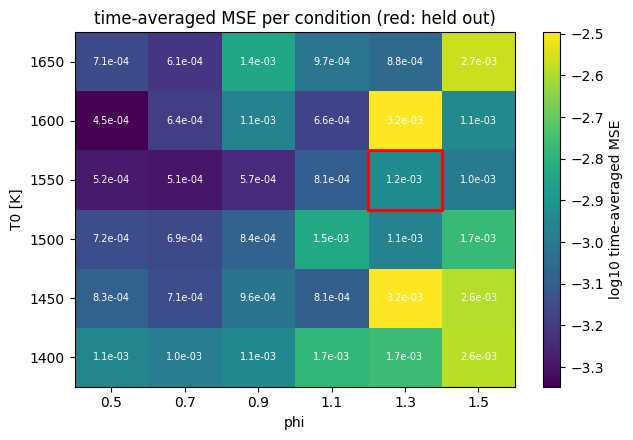

In [4]:
span = model["u_max"] - model["u_min"]
t_obs = ref["t"]
pred = {}
for i in range(len(ref["ics"])):
    pred[i] = pt.predict(model, ref, i, t_obs)                       # normalized (T, 53)
target = {i: (np.concatenate([ref["states"][i][:, :len(ref["species"])],
                              ref["temperature"][:, i:i + 1]], axis=1) - model["u_min"]) / span
          for i in pred}
rows = []
for i in pred:
    err = (pred[i] - target[i]) ** 2
    T0, phi = ref["ics"][i]
    rows.append({"T0": T0, "phi": phi, "split": "test" if ref["is_test"][i] else "train",
                 "mse": err.mean(), "mse_T": err[:, -1].mean(),
                 "mse_species": err[:, :-1].mean()})
cond = pd.DataFrame(rows)
tr = cond[cond.split == "train"]
print(f"train (35): median {tr.mse.median():.3e}, min {tr.mse.min():.3e}, max {tr.mse.max():.3e}")
print(f"held-out 1550 K / phi 1.3: {cond[cond.split == 'test'].mse.iloc[0]:.3e}")

grid = cond.pivot(index="T0", columns="phi", values="mse")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
im = ax.imshow(np.log10(grid.values), origin="lower", cmap="viridis", aspect="auto")
ax.set_xticks(range(len(grid.columns)), [f"{p:g}" for p in grid.columns])
ax.set_yticks(range(len(grid.index)), [f"{T:g}" for T in grid.index])
ax.set_xlabel("phi"); ax.set_ylabel("T0 [K]")
for (r, c), val in np.ndenumerate(grid.values):
    ax.text(c, r, f"{val:.1e}", ha="center", va="center", fontsize=7, color="w")
ti = list(grid.index).index(1550.0); pi = list(grid.columns).index(1.3)
ax.add_patch(plt.Rectangle((pi - .5, ti - .5), 1, 1, fill=False, ec="r", lw=2))
fig.colorbar(im, label="log10 time-averaged MSE")
ax.set_title("time-averaged MSE per condition (red: held out)")
fig.tight_layout()

### Which states carry the error

Time-averaged MSE per state, median over the 35 training conditions, largest first. The
temperature and the major species are listed among the largest contributors only if they
are; minor radicals with tiny absolute mass fractions can still carry large normalized error.

In [5]:
per_state = np.median(np.stack([((pred[i] - target[i]) ** 2).mean(axis=0)
                                for i in pred if not ref["is_test"][i]]), axis=0)
order = np.argsort(per_state)[::-1]
top = pd.DataFrame({"state": [ref["names"][j] for j in order[:15]],
                    "median MSE (train)": per_state[order[:15]]})
print(f"median over states: {np.median(per_state):.3e}; temperature: "
      f"{per_state[-1]:.3e} (rank {int(np.where(order == len(per_state) - 1)[0][0]) + 1} of 53)")
top.style.format({"median MSE (train)": "{:.2e}"})

median over states: 4.884e-04; temperature: 1.329e-03 (rank 11 of 53)


,state,median MSE (train)
0,HO2,2.55e-03
1,O,2.38e-03
2,CH3O,2.17e-03
3,CH2O,1.98e-03
4,H2O2,1.75e-03
5,NNH,1.73e-03
6,H,1.72e-03
7,C2H6,1.61e-03
8,OH,1.60e-03
9,NO2,1.59e-03


## Trajectories: held-out condition and its nearest training condition

Prediction on a dense grid (line) against the reference observations (markers), physical
units. Main species as in `plot_trajectory.py`.

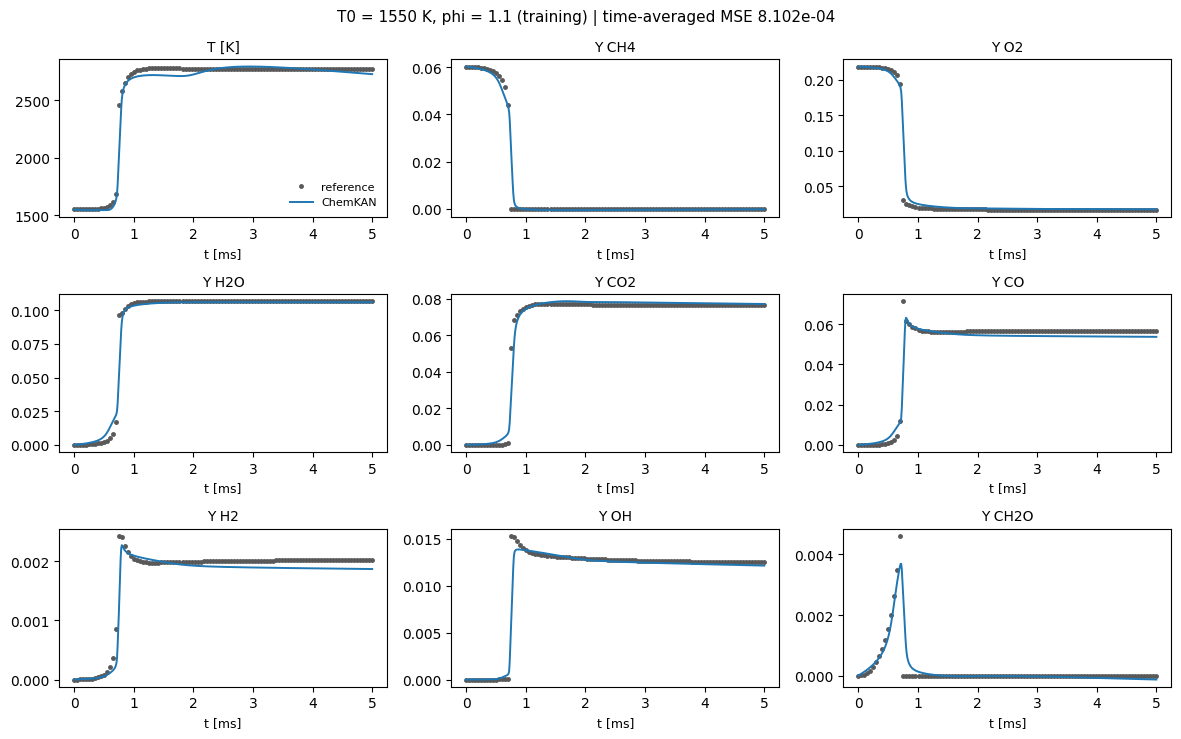

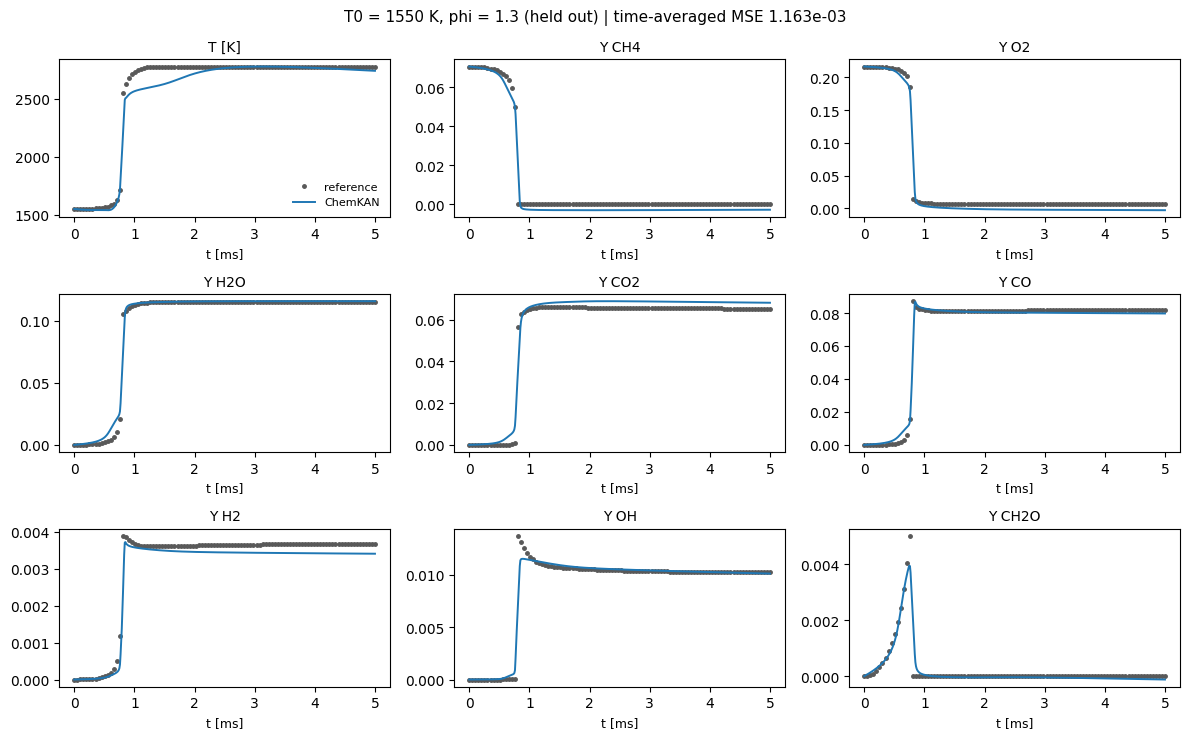

In [6]:
dense_t = np.linspace(t_obs[0], t_obs[-1], 501)
panels = ["T"] + pt.MAIN_SPECIES["methane"]
for i in pt.default_conditions("methane", ref):
    dense = pt.predict(model, ref, i, dense_t) * span + model["u_min"]
    fig, axes = plt.subplots(3, 3, figsize=(12, 7.5))
    for ax, name in zip(axes.flat, panels):
        j = ref["names"].index(name)
        obs = ref["temperature"][:, i] if name == "T" else ref["states"][i][:, j]
        ax.plot(t_obs * 1e3, obs, "o", ms=2.5, color="0.35", label="reference")
        ax.plot(dense_t * 1e3, dense[:, j], "-", lw=1.4, color="tab:blue", label="ChemKAN")
        ax.set_title("T [K]" if name == "T" else f"Y {name}", fontsize=10)
        ax.set_xlabel("t [ms]", fontsize=9)
    axes.flat[0].legend(fontsize=8, frameon=False)
    role = "held out" if ref["is_test"][i] else "training"
    fig.suptitle(f"{ref['labels'][i]} ({role}) | time-averaged MSE "
                 f"{cond.mse.iloc[i]:.3e}", fontsize=11)
    fig.tight_layout()

## Temperature for all 36 conditions

Rows: T0; columns: phi. Grey: reference; blue: ChemKAN (dense grid); red frame: held out.

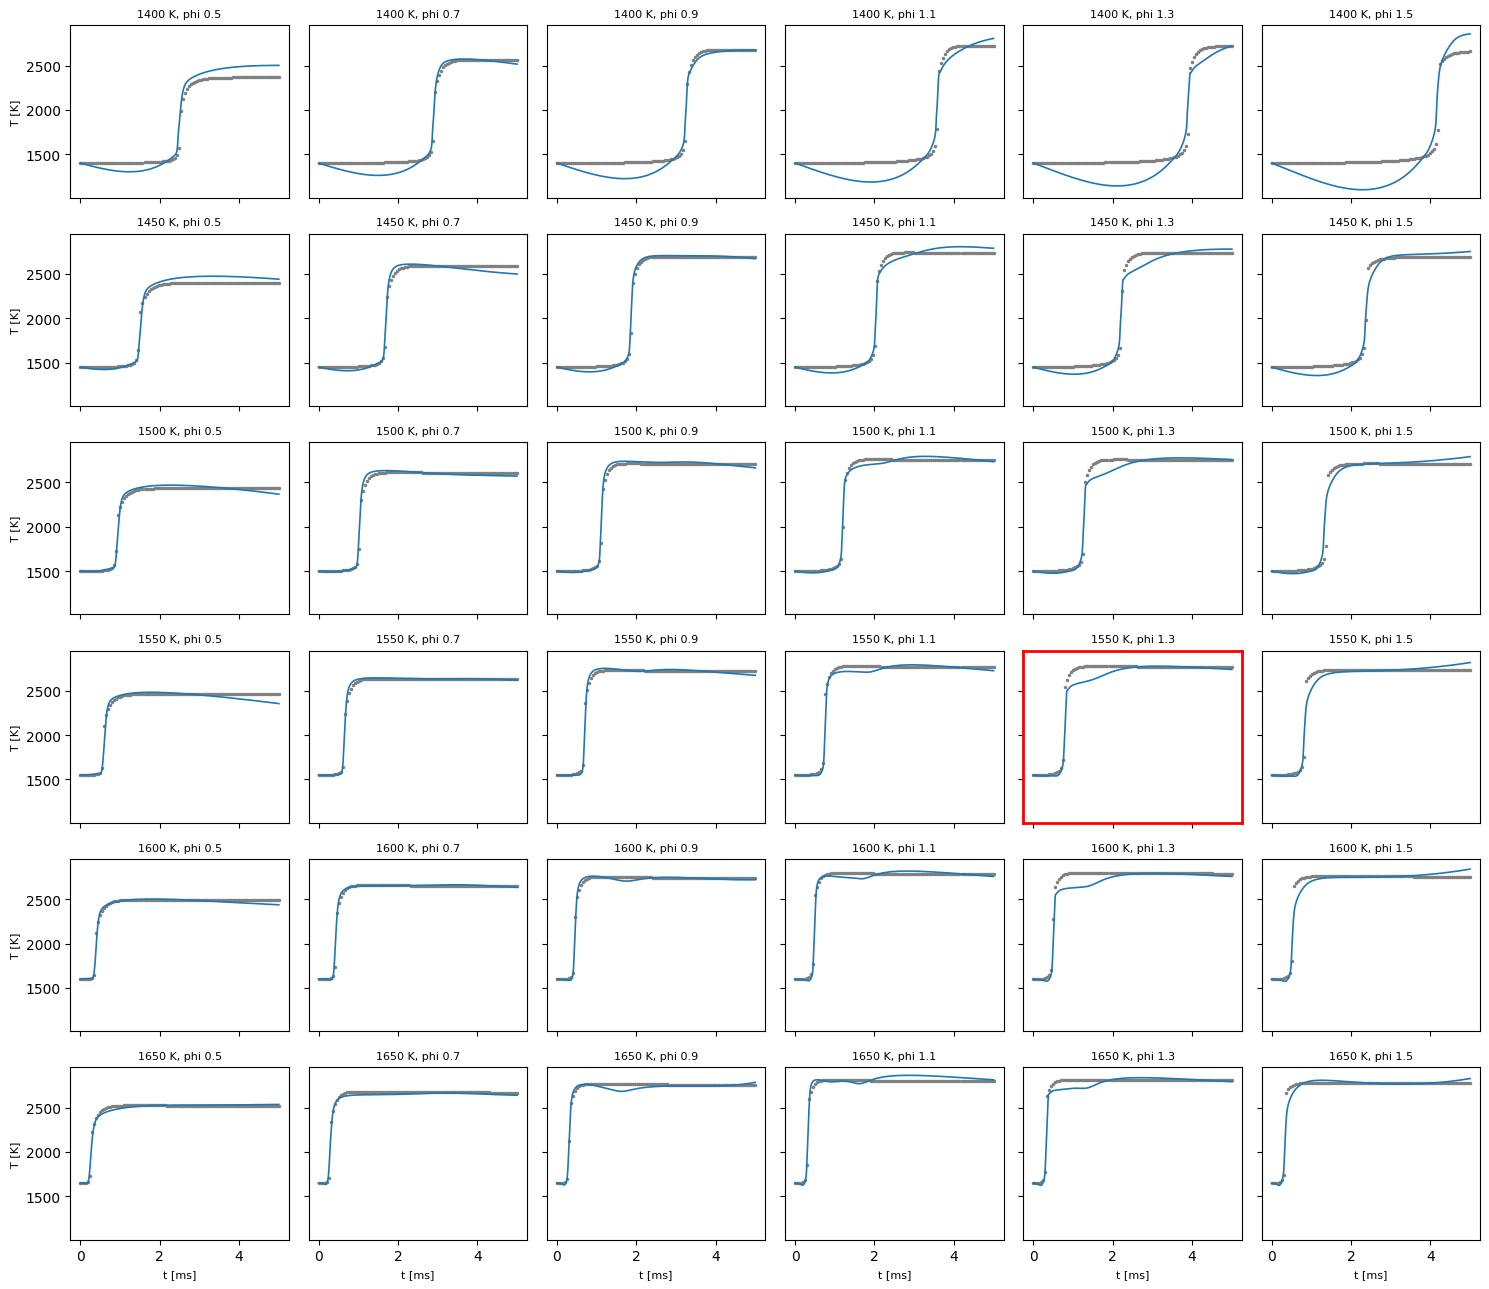

In [7]:
T0s, phis = sorted(set(ref["ics"][:, 0])), sorted(set(ref["ics"][:, 1]))
fig, axes = plt.subplots(len(T0s), len(phis), figsize=(15, 13), sharex=True, sharey=True)
dense_T = {}
for i in pred:
    T0, phi = ref["ics"][i]
    dense_T[i] = pt.predict(model, ref, i, dense_t)[:, -1] * span[-1] + model["u_min"][-1]
    ax = axes[T0s.index(T0), phis.index(phi)]
    ax.plot(t_obs * 1e3, ref["temperature"][:, i], "o", ms=1.5, color="0.5")
    ax.plot(dense_t * 1e3, dense_T[i], "-", lw=1.2, color="tab:blue")
    ax.set_title(f"{T0:g} K, phi {phi:g}", fontsize=8)
    if ref["is_test"][i]:
        for s in ax.spines.values():
            s.set_color("r"); s.set_linewidth(2)
for ax in axes[-1]:
    ax.set_xlabel("t [ms]", fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("T [K]", fontsize=8)
fig.tight_layout()

## Ignition delay and temperature rise

Our analysis, not a paper figure: ignition delay = time of the largest dT/dt (the paper's
definition for hydrogen, Sec. III B), from `numpy.gradient` on the same 501-point grid for
the reference (dense Cantera temperature, interpolated) and the model; temperature rise =
final minus initial temperature.

|delay error|: median 1.2%, max 5.8% (grid step 0.010 ms)
temperature rise: model median 1161 K vs reference 1168 K


,T0,phi,split,delay_ref_ms,delay_model_ms,rise_ref_K,rise_model_K,delay_rel_err
0,1400.0,0.5,train,2.51,2.46,965.1116,1101.318848,-0.0199
1,1400.0,0.7,train,2.90,2.86,1163.0800,1115.699219,-0.0138
2,1400.0,0.9,train,3.26,3.27,1273.1533,1273.093750,0.0031
3,1400.0,1.1,train,3.60,3.60,1322.6377,1405.760254,0.0000
4,1400.0,1.3,train,3.91,3.88,1317.7379,1322.152832,-0.0077
5,1400.0,1.5,train,4.22,4.15,1258.4495,1457.281982,-0.0166
6,1450.0,0.5,train,1.48,1.48,948.7419,990.551819,0.0000
7,1450.0,0.7,train,1.69,1.66,1134.8639,1048.935547,-0.0178
8,1450.0,0.9,train,1.87,1.88,1238.6607,1222.174316,0.0053
9,1450.0,1.1,train,2.05,2.05,1286.1770,1339.214844,0.0000


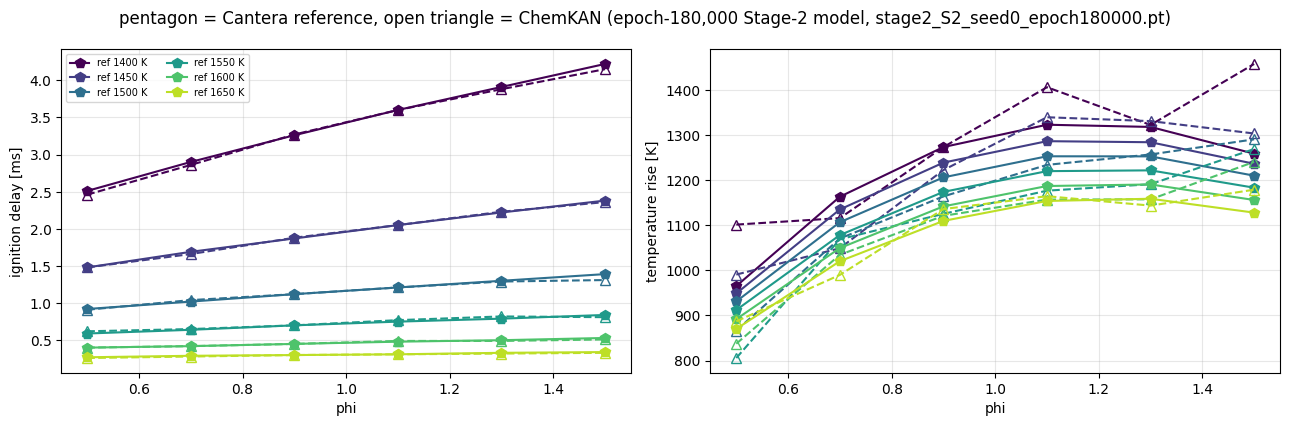

In [8]:
obs_t, obs_T = ref["observed_temperature"]
rows = []
for i in pred:
    T_ref = np.interp(dense_t, obs_t, obs_T[:, i])
    tau_ref = dense_t[np.argmax(np.gradient(T_ref, dense_t))]
    tau_mod = dense_t[np.argmax(np.gradient(dense_T[i], dense_t))]
    T0, phi = ref["ics"][i]
    rows.append({"T0": T0, "phi": phi, "split": "test" if ref["is_test"][i] else "train",
                 "delay_ref_ms": tau_ref * 1e3, "delay_model_ms": tau_mod * 1e3,
                 "rise_ref_K": T_ref[-1] - T_ref[0], "rise_model_K": dense_T[i][-1] - dense_T[i][0]})
ign = pd.DataFrame(rows)
ign["delay_rel_err"] = (ign.delay_model_ms - ign.delay_ref_ms) / ign.delay_ref_ms

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
colours = plt.cm.viridis(np.linspace(0, .9, len(T0s)))
for c, T0 in zip(colours, T0s):
    d = ign[ign.T0 == T0].sort_values("phi")
    axes[0].plot(d.phi, d.delay_ref_ms, "p-", color=c, ms=7, label=f"ref {T0:g} K")
    axes[0].plot(d.phi, d.delay_model_ms, "^--", color=c, ms=7, mfc="none")
    axes[1].plot(d.phi, d.rise_ref_K, "p-", color=c, ms=7)
    axes[1].plot(d.phi, d.rise_model_K, "^--", color=c, ms=7, mfc="none")
axes[0].set_ylabel("ignition delay [ms]"); axes[1].set_ylabel("temperature rise [K]")
for ax in axes:
    ax.set_xlabel("phi"); ax.grid(alpha=.3)
axes[0].legend(fontsize=7, ncol=2)
fig.suptitle("pentagon = Cantera reference, open triangle = ChemKAN "
             f"(epoch-{model['epochs']:,} Stage-2 model, {CKPT.name})")
fig.tight_layout()
FIG_DIR = RUN / "figures"
FIG_DIR.mkdir(exist_ok=True)
for ext in ("png", "pdf"):
    fig.savefig(FIG_DIR / f"methane_ignition_delay_rise_S2_epoch{model['epochs']}.{ext}", dpi=200)
print(f"|delay error|: median {ign.delay_rel_err.abs().median():.1%}, max {ign.delay_rel_err.abs().max():.1%} "
      f"(grid step {1e3 * (dense_t[1] - dense_t[0]):.3f} ms)")
print(f"temperature rise: model median {ign.rise_model_K.median():.0f} K vs reference "
      f"{ign.rise_ref_K.median():.0f} K")
ign.round(4)

## Observations (epoch-180,000 Stage-2 snapshot, best by training MSE; seed 0)

- **Snapshot choice:** the final 200k model sits on a loss spike (training mean 2.89e-3,
  worst condition 1.18e-2); the 180k, 185k and 190k snapshots agree within 0.6 % (training
  mean 1.22e-3), and 180k has the lowest training mean.
- **Overall:** time-averaged MSE median 9.72e-4 over the 35 training conditions (4.5e-4 to
  3.2e-3); held-out 1550 K / phi 1.3: 1.16e-3, inside the training range. At 50k the same
  numbers were 1.88e-3 (6.3e-4 to 9.3e-3) and 1.57e-3.
- **Where it is worse:** the rich conditions, phi 1.3-1.5 (1.0e-3 to 3.2e-3; worst 1450 K and
  1600 K at phi 1.3). From about 1500 K up at phi >= 1.1 the model's temperature rises in two
  steps (a shoulder a few hundred K below the final value, then a slow climb) where the
  reference jumps at once. At 1400 K the model's temperature still dips before ignition,
  increasingly with phi; ignition itself is on time.
- **Ignition delay** (argmax dT/dt, 0.010 ms grid): median |error| 1.2 %, max 5.8 % (3.8 % and
  18.5 % at 50k).
- **Temperature rise:** median 1161 K vs 1168 K (reference); after ignition the model's
  temperature still drifts slightly where the reference is flat.
- **Per state:** the largest normalized errors are radicals and intermediates (HO2, O, CH3O,
  CH2O, H2O2); the temperature ranks 11th of 53 (1.33e-3).
- **Not converged:** the training loss was still falling at 200k (1,000-epoch median 2.01e-3 at
  100k, 1.71e-3 at 185k, 1.43e-3 at 200k).
